# 路线 B 英国国债零息曲线再应用

路线 A 复现了教材算例。路线 B 使用英格兰银行公布的 2025 年月末名义即期零息利率，按统一现金流规则计算标准化债券的参考价格，再比较两种校准方法。

**数据口径**　央行利率是发布的市场拟合估计。参考价格由这些利率折现计算。英国 DMO 的 4% Treasury Gilt 2031 发行文件提供实验采用的常规票息率及半年付款频率。实验按每 £100 面值计算，付息债券从 1 年开始每半年付 £2。

[英格兰银行官方数据档案](https://www.bankofengland.co.uk/statistics/yield-curves) · [英国 DMO 发行文件](https://www.dmo.gov.uk/media/52dlkrjw/prosp210224.pdf)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from run_route_b import verify_release

results_dir = Path("results_b")
release = verify_release(results_dir)
reference = pd.read_csv(results_dir / "reference_rates.csv")
coverage = pd.read_csv(results_dir / "coverage_audit.csv")
metrics = pd.read_csv(results_dir / "metrics.csv")
pairs = pd.read_csv(results_dir / "paired_metrics.csv", parse_dates=["as_of_date"])
curves = pd.read_csv(results_dir / "curves.csv")
cashflows = pd.read_csv(results_dir / "cashflow_valuation.csv")
display(Markdown(
    f"**来源清单与结果哈希校验通过。** "
    f"{reference['as_of_date'].nunique()} 个月末，{len(reference)} 个发布利率，"
    f"{metrics['converged'].sum()}/{len(metrics)} 组校准收敛。"
))

**来源清单与结果哈希校验通过。** 12 个月末，228 个发布利率，48/48 组校准收敛。

## 1 原始数据覆盖

2025 年 7–12 月，半年期利率在全期限和短端两张即期表都为空。研究统一采用全年都有发布值的 **1–10 年**区间。下面列出半年期缺失的原始单元格。正式结果在 19 个共同期限上评分。

In [2]:
absent = coverage.loc[coverage["status"].eq("not_published")]
display(absent[["as_of_date", "full_curve_cell", "short_end_cell"]].style.hide())

as_of_date,full_curve_cell,short_end_cell
2025-07-31,4. spot curve!B11,"3. spot, short end!G12"
2025-08-29,4. spot curve!B12,"3. spot, short end!G13"
2025-09-30,4. spot curve!B13,"3. spot, short end!G14"
2025-10-31,4. spot curve!B14,"3. spot, short end!G15"
2025-11-28,4. spot curve!B15,"3. spot, short end!G16"
2025-12-31,4. spot curve!B16,"3. spot, short end!G17"


## 2 按月配对比较

每个月内，线性插值和自然三次样条使用同一档可见报价。两档都评估 2.5、5.5、8.5 年的留出债券。下面的差值是 **样条减线性**，负数代表样条误差较小。MAE 以每 £100 面值的金额计，利率 RMSE 以基点（bp）计。

In [3]:
delta_columns = {
    "mae_delta_spline_minus_linear": "Holdout pricing MAE delta (GBP)",
    "rmse_delta_bp_spline_minus_linear": "Zero-rate RMSE delta (bp)",
}
summary = []
for density, month_group in pairs.groupby("density", sort=False):
    for field, label in delta_columns.items():
        summary.append({
            "density": density, "metric": label, "months": len(month_group),
            "spline_lower_error": int(month_group[field].lt(0).sum()),
            "median_delta": month_group[field].median(),
        })
display(pd.DataFrame(summary).style.format({"median_delta": "{:+.6f}"}).hide())
display(Markdown(f"最大训练绝对价格残差约为 **{metrics['max_train_price_error'].max():.2e} GBP**。"))

density,metric,months,spline_lower_error,median_delta
dense,Holdout pricing MAE delta (GBP),12,12,-0.005518
dense,Zero-rate RMSE delta (bp),12,12,-0.071018
sparse,Holdout pricing MAE delta (GBP),12,12,-0.004153
sparse,Zero-rate RMSE delta (bp),12,12,-0.157976


最大训练绝对价格残差约为 **3.15e-11 GBP**。

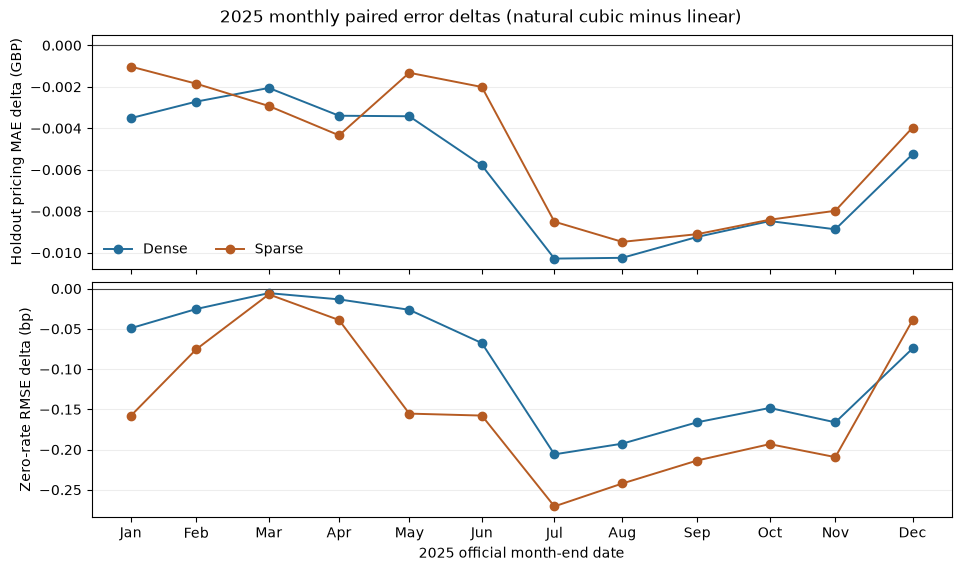

In [4]:
density_colors = {"dense": "#226D9A", "sparse": "#B65B22"}
fig, axes = plt.subplots(2, 1, figsize=(9.5, 5.6), sharex=True, layout="constrained")
for ax, (field, label) in zip(axes, delta_columns.items(), strict=True):
    for density, month_group in pairs.groupby("density", sort=False):
        month_group = month_group.sort_values("as_of_date")
        ax.plot(month_group["as_of_date"], month_group[field], marker="o",
                linewidth=1.4, color=density_colors[density], label=density.capitalize())
    ax.axhline(0, color="#444444", linewidth=0.8)
    ax.set_ylabel(label)
    ax.grid(axis="y", alpha=0.22)
axes[0].legend(frameon=False, ncol=2)
month_dates = pairs["as_of_date"].drop_duplicates().sort_values()
axes[-1].set_xticks(month_dates, month_dates.dt.strftime("%b"))
axes[-1].set_xlabel("2025 official month-end date")
fig.suptitle("2025 monthly paired error deltas (natural cubic minus linear)")
plt.show()

## 3 查看样本期最后一个月

上排叠加两档报价密度下的曲线。参考和拟合曲线可能很接近，因此下排同时显示各期限的有符号误差。灰色竖线标记三个测试期限。

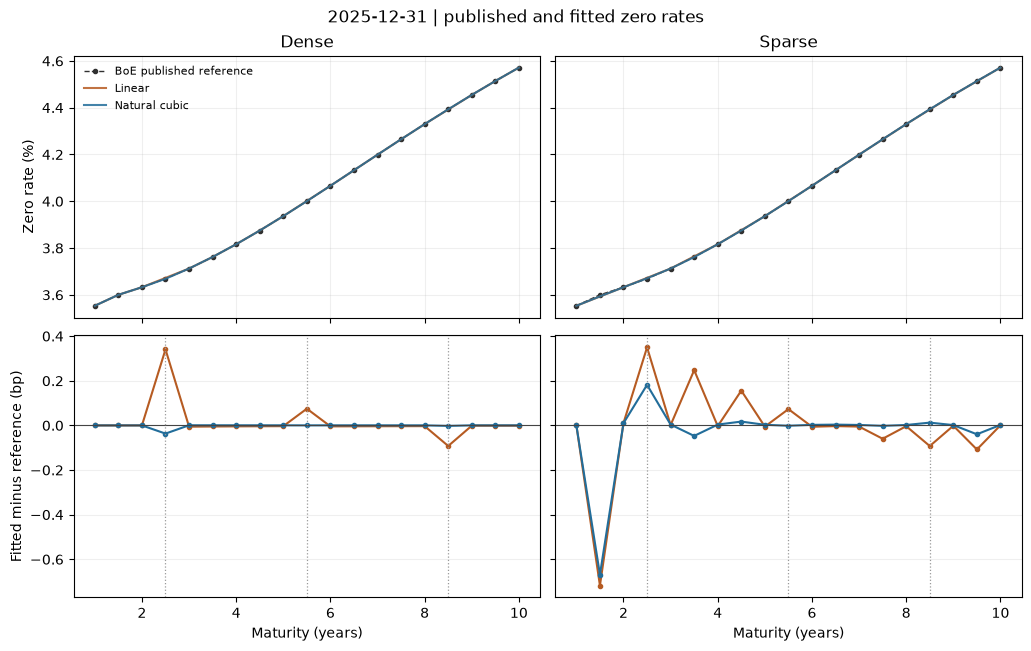

In [5]:
example_date = reference["as_of_date"].max()
example = curves.loc[curves["as_of_date"].eq(example_date)]
method_colors = {"linear": "#B65B22", "natural_cubic": "#226D9A"}
method_labels = {"linear": "Linear", "natural_cubic": "Natural cubic"}
fig, axes = plt.subplots(2, 2, figsize=(10.2, 6.4), sharex=True, sharey="row", layout="constrained")
for i, density in enumerate(("dense", "sparse")):
    top, bottom = axes[:, i]
    panel = example.loc[example["density"].eq(density)]
    anchor = panel.loc[panel["method"].eq("linear")]
    top.plot(anchor["maturity_years"], 100 * anchor["reference_rate"], color="#303030",
             marker=".", linewidth=1, linestyle="--", label="BoE published reference")
    for method, group in panel.groupby("method", sort=False):
        color = method_colors[method]
        top.plot(group["maturity_years"], 100 * group["fitted_rate"], color=color,
                 alpha=0.85, label=method_labels[method])
        bottom.plot(group["maturity_years"], 10_000 * (group["fitted_rate"] - group["reference_rate"]),
                    color=color, marker=".", label=method_labels[method])
    bottom.axhline(0, color="#444444", linewidth=0.8)
    for maturity in release["holdout_years"]:
        bottom.axvline(maturity, color="#999999", linestyle=":", linewidth=0.9)
    top.set_title(density.capitalize())
    bottom.set_xlabel("Maturity (years)")
    top.grid(alpha=0.2)
    bottom.grid(axis="y", alpha=0.2)
axes[0, 0].set_ylabel("Zero rate (%)")
axes[1, 0].set_ylabel("Fitted minus reference (bp)")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle(f"{example_date} | published and fitted zero rates")
plt.show()

## 4 逐笔追溯留出债券

以同月 2.5 年期债券为例，逐笔现值相加就是参考价格。可按工作表及单元格回查原始利率，或用日期与付款期限联接参考利率 CSV，定位档案与 SHA-256。

In [6]:
example_bond = cashflows.loc[cashflows["as_of_date"].eq(example_date)
                             & cashflows["bond_maturity_years"].eq(2.5)]
columns = ["payment_years", "cashflow_gbp", "zero_rate_decimal", "discount_factor",
           "present_value_gbp", "source_sheet", "source_cell"]
display(example_bond[columns].style.format({
    "payment_years": "{:.1f}", "cashflow_gbp": "{:.2f}",
    "zero_rate_decimal": "{:.8f}", "discount_factor": "{:.8f}",
    "present_value_gbp": "{:.8f}",
}).hide())
display(Markdown(f"**参考价格 = £{example_bond['present_value_gbp'].sum():.8f}**（每 £100 面值）。"))

payment_years,cashflow_gbp,zero_rate_decimal,discount_factor,present_value_gbp,source_sheet,source_cell
1.0,2.00,0.03553327,0.96509062,1.93018125,4. spot curve,C16
1.5,2.00,0.03600159,0.94742985,1.89485970,4. spot curve,D16
2.0,2.00,0.03632526,0.92992576,1.85985153,4. spot curve,E16
2.5,102.00,0.03669046,0.91235497,93.06020736,4. spot curve,F16


**参考价格 = £98.74509984**（每 £100 面值）。

## 5 解读范围

结果适用于 2025 年这 12 个英国月末截面、1–10 年期限、上述标准化付款安排和固定留出方案。路线 A 原实验使用 0.5–10 年及不同的付款起点，跨路线对照时应标明口径差异。